# Рынок жилья Парижа и ближнего пригорода, 2021–2024 — EDA

Нотариальные сделки из открытого реестра DVF (департаменты 75, 92, 93, 94). Анализ построен на
гипотезах: каждая проверяется регрессией с фиксированным эффектом локации (ячейка 300 × 300 м),
бутстрепом или перестановочным тестом. Интерактивная версия с картами — `docs/index.html`.

Исходник ноутбука — `analysis.py` (ячейки `# %%`), сборка — `python make_notebook.py`.

In [1]:
import os
import shutil
import sys
import tempfile
import warnings

import pandas as pd
import plotly
import plotly.io as pio
from IPython.display import Image, display

sys.path.insert(0, "src")
warnings.filterwarnings("ignore", category=FutureWarning)
from dvf import analysis as A   # noqa: E402
from dvf import figures as F    # noqa: E402
from dvf.clean import load      # noqa: E402

# kaleido не понимает не-ASCII пути к plotly.js — кладём копию во временную папку
_js = os.path.join(tempfile.gettempdir(), f"plotly-{plotly.__version__}.min.js")
shutil.copy(os.path.join(os.path.dirname(plotly.__file__), "package_data", "plotly.min.js"), _js)
pio.kaleido.scope.plotlyjs = _js
pd.set_option("display.precision", 3)


def show(fig, width=1000):
    """Статичная картинка: GitHub не рендерит интерактивный Plotly в ноутбуках."""
    display(Image(fig.to_image("png", width=width, scale=1)))

## 1. Данные: что такое одна сделка

Строка DVF — сделка × участок × помещение × вид угодий, и полная цена сделки повторена в каждой.
Оставляем сделки ровно с одним жильём, без коммерческих помещений и с одной ценой; подсобные
помещения (парковки, погреба) остаются в цене.

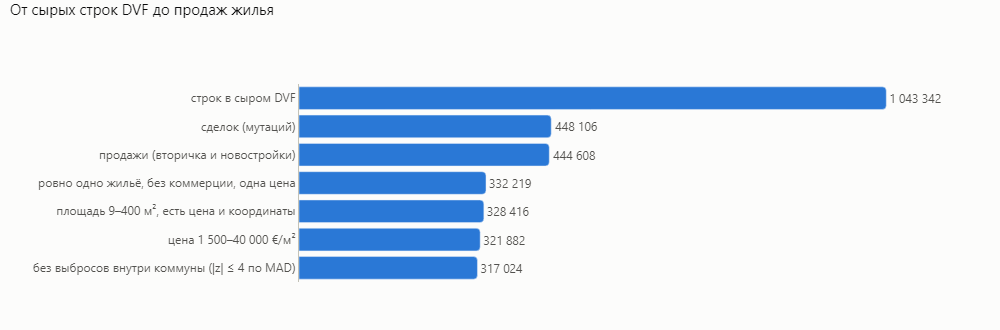

,шаг,число
0,строк в сыром DVF,1043342
1,сделок (мутаций),448106
2,продажи (вторичка и новостройки),444608
3,"ровно одно жильё, без коммерции, одна цена",332219
4,"площадь 9–400 м², есть цена и координаты",328416
5,цена 1 500–40 000 €/м²,321882
6,без выбросов внутри коммуны (|z| ≤ 4 по MAD),317024


In [2]:
s, steps = load()
R = A.run_all(s)
s = R["s"]
show(F.funnel(steps))
pd.DataFrame(steps, columns=["шаг", "число"])

In [3]:
R["overview"]["by_year"].pivot(index="year", columns="zone", values=["n", "med"]).round(0)

n               med         
zone    Париж пригород    Париж пригород
year                                    
2021  30264.0  61007.0  10938.0   5700.0
2022  32917.0  59518.0  10806.0   5833.0
2023  26675.0  44389.0  10267.0   5635.0
2024  24169.0  38085.0   9694.0   5316.0

## 2. Локация решает почти всё

Доля разброса log(€/м²) квартир, которую объясняет локация, — отсюда фиксированный эффект ячейки
300 м во всех дальнейших сравнениях.

In [4]:
pd.Series(R["location"]).round(3)

commune          0.749
cell             0.811
cell_attrs       0.825
n_cells       5122.000
dtype: float64

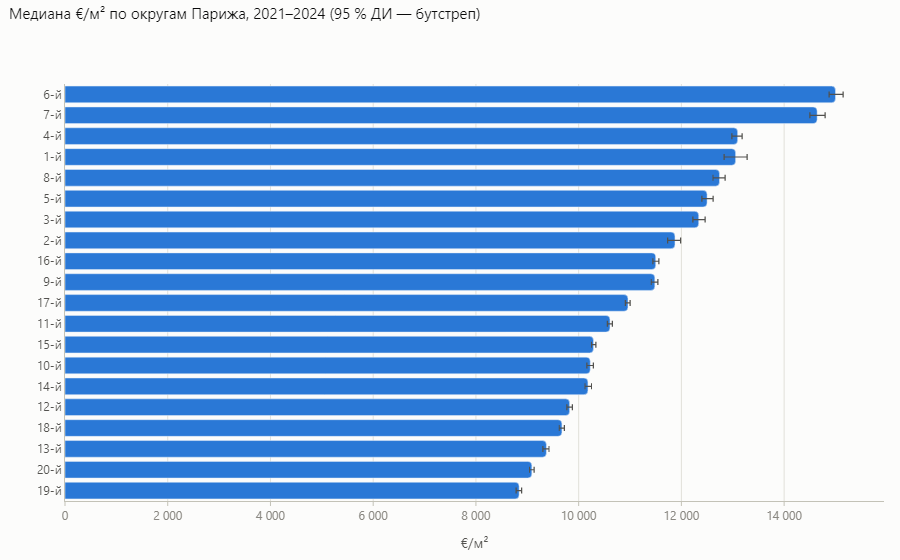

Спирмен «уровень округа — изменение 2024 к 2021»: ρ = 0.94, p = 1.5e-09


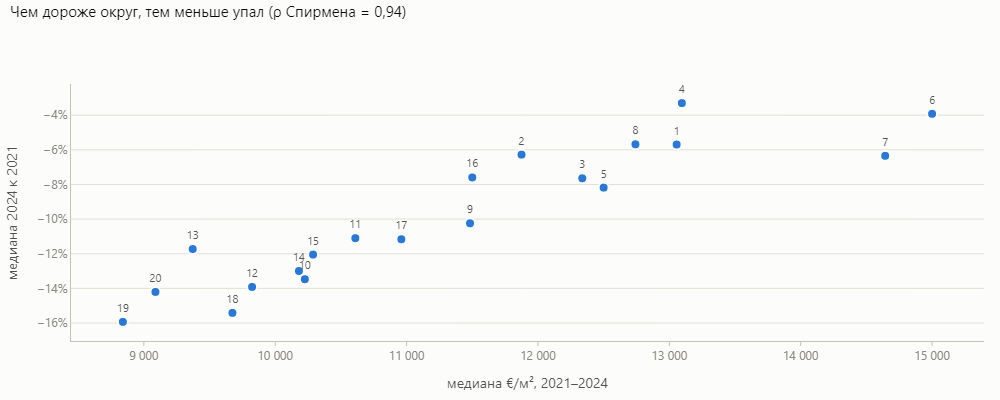

In [5]:
show(F.arrondissements(R["arr"]), 900)
print("Спирмен «уровень округа — изменение 2024 к 2021»: ρ = %.2f, p = %.1e" % R["arr_rho"])
show(F.arr_level_change(R["arr"], R["arr_rho"][0]))

In [6]:
dn = R["donut"]
print("Эффект границы Парижа (4–7 км от центра, с поправкой на расстояние): %+.1f%% [%+.1f; %+.1f]"
      % tuple(100 * x for x in dn["border"]))
dn["border_med"]

Эффект границы Парижа (4–7 км от центра, с поправкой на расстояние): +44.2% [+29.6; +60.5]


{'Париж': 10162.917087967644, 'пригород': 7200.0}

## 3. Гипотеза: после подъёма ставок цены упали

Гедонический индекс: log(€/м²) ~ дамми кварталов + FE ячейки + площадь (log, квадрат) + комнаты +
новостройка; ошибки кластерные по ячейкам. Пунктир — наивная медиана.

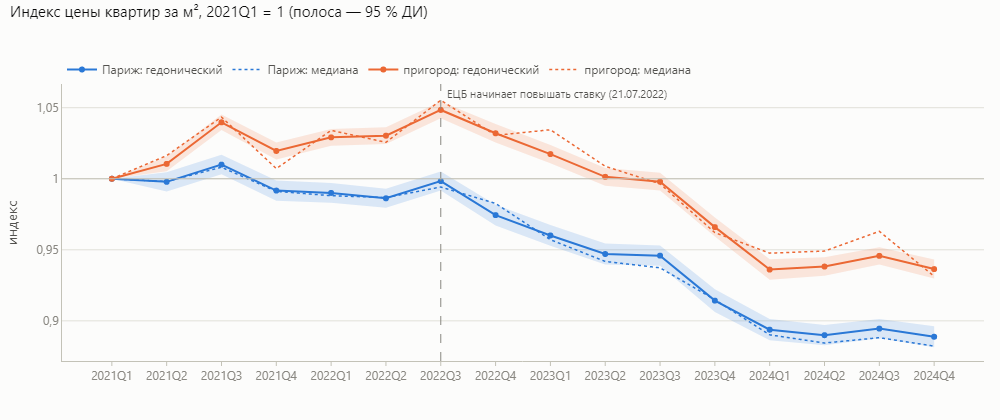

,peak_q,peak,last,last_lo,last_hi,from_peak,naive_last,r2
Париж,2021Q3,1.01,0.889,0.881,0.896,-0.12,0.882,0.395
пригород,2022Q3,1.048,0.936,0.93,0.943,-0.107,0.931,0.783


In [7]:
show(F.hedonic_index(R["index"]["table"]))
pd.DataFrame(R["index"]["summary"]).T

In [8]:
R["mix"]   # состав сделок по годам — проверка наивной медианы

,zone,year,small,med_surface,new,dist
0,Париж,2021,0.270,43.0,0.003,3.633
1,Париж,2022,0.264,44.0,0.002,3.624
2,Париж,2023,0.288,42.0,0.002,3.589
3,Париж,2024,0.291,42.0,0.001,3.576
4,пригород,2021,0.116,57.0,0.165,9.179
5,пригород,2022,0.117,56.0,0.142,9.108
6,пригород,2023,0.131,55.0,0.122,9.051
7,пригород,2024,0.133,56.0,0.097,8.981


## 4. Гипотеза: объём падает сильнее цены

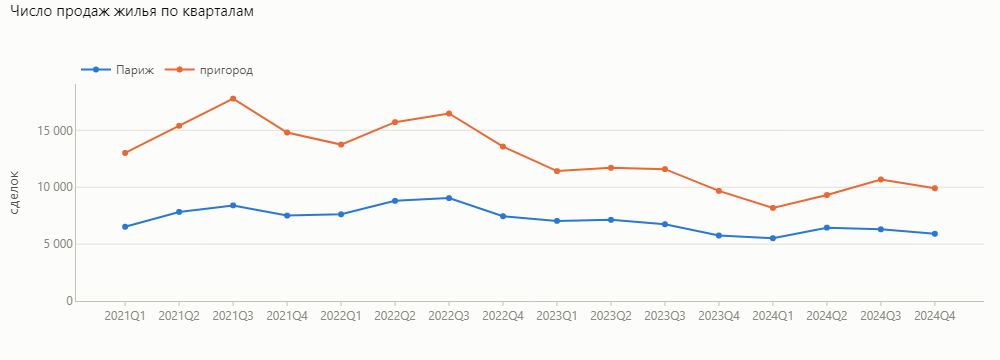

Число сделок 2024 к 2021: {'Париж': -0.201, 'пригород': -0.376}
По типу: {'вторичка': -0.287, 'новостройки': -0.632}
Коммуны, вторичка: Спирмен(Δобъёма, Δцены) = -0.248, p = 0.0044, n = 130


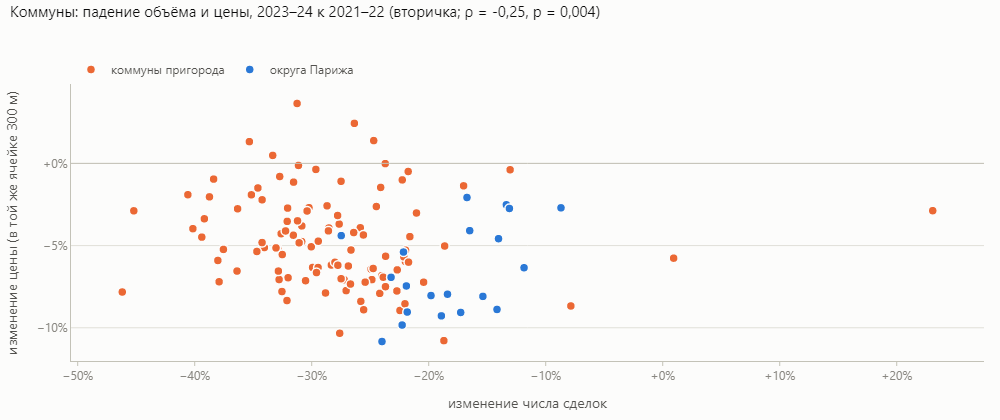

In [9]:
v = R["volumes"]
show(F.volumes(v["quarterly"]))
print("Число сделок 2024 к 2021:", {k: round(x, 3) for k, x in v["vol_change"].items()})
print("По типу:", {k: round(x, 3) for k, x in v["kind_change"].items()})
print("Коммуны, вторичка: Спирмен(Δобъёма, Δцены) = %.3f, p = %.4f, n = %d" % (v["rho"], v["p"], len(v["communes"])))
show(F.volume_vs_price(v["communes"], v["rho"], v["p"]))

## 5. Гипотеза «пончика»: пригород выиграл у Парижа

Одна регрессия: дамми кварталов + дамми «квартал × пригород» при FE ячейки.

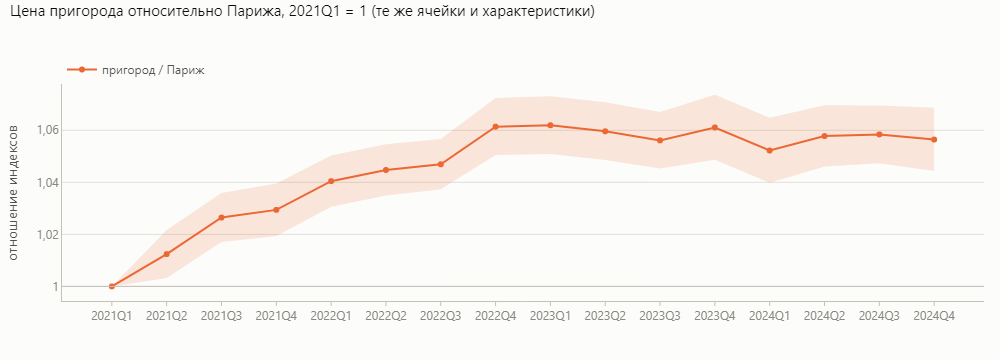

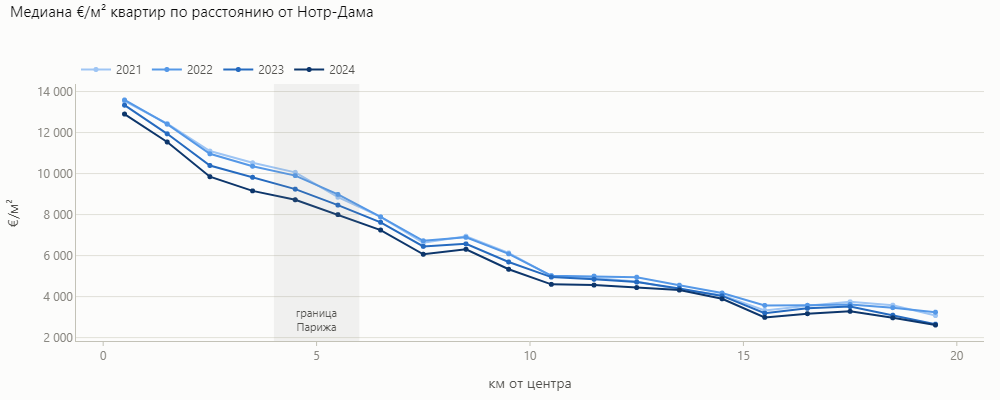

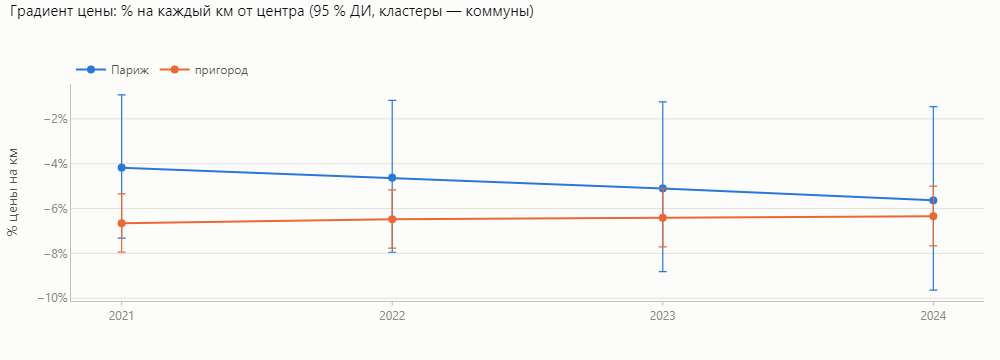

zone,Париж,всё,пригород
year,,,
2021,-0.042,-0.085,-0.067
2022,-0.046,-0.083,-0.065
2023,-0.051,-0.083,-0.064
2024,-0.056,-0.083,-0.063


In [10]:
show(F.donut_gap(dn["gap"]))
show(F.distance_profile(dn["profile"]))
show(F.gradient(dn["gradient"]))
dn["gradient"].pivot(index="year", columns="zone", values="slope")

## 6. Гипотеза: маленькие квартиры дороже за м²

«Как есть» (медианы) против «в той же ячейке 300 м». В пригороде знак премии больших квартир
меняется — парадокс Симпсона.

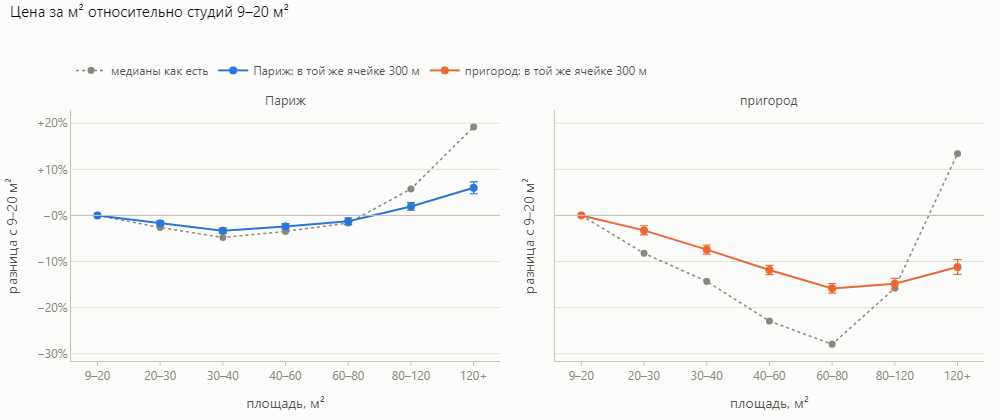

raw          within         
zone    Париж пригород  Париж пригород
bin                                   
9–20    0.000    0.000  0.000    0.000
20–30  -0.026   -0.082 -0.017   -0.032
30–40  -0.048   -0.143 -0.033   -0.074
40–60  -0.035   -0.229 -0.024   -0.118
60–80  -0.017   -0.279 -0.013   -0.158
80–120  0.057   -0.158  0.019   -0.148
120+    0.192    0.134  0.060   -0.112

In [11]:
show(F.size_premium(R["size"]))
R["size"].pivot(index="bin", columns="zone", values=["raw", "within"]).loc[A.SIZE_LABELS]

## 7. Сколько стоит новизна (пригород)

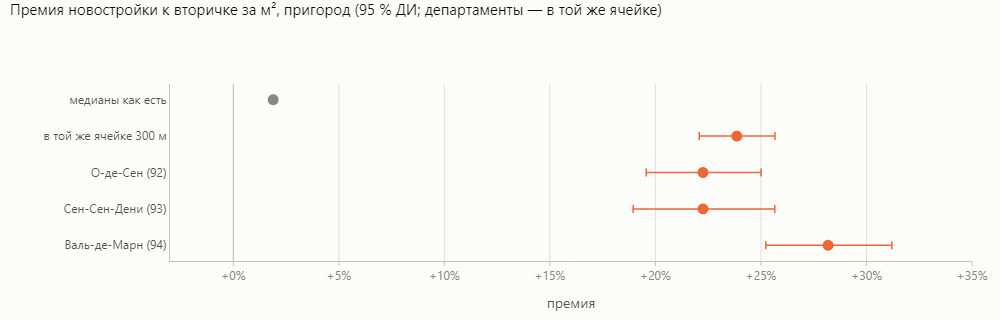

Медианы как есть: +1.9%; в той же ячейке: +23.9% [+22.1; +25.7]


In [12]:
nb = R["new"]
show(F.new_build(nb))
print("Медианы как есть: %+.1f%%; в той же ячейке: %+.1f%% [%+.1f; %+.1f]"
      % (100 * nb["raw"], *(100 * x for x in nb["within"])))

## 8. Гипотеза: Олимпиада подняла цены у Олимпийской деревни

Разность разностей на средних остатках по коммунам 93; основной тест — перестановочный
(все наборы из трёх коммун), потому что кластерные ошибки при трёх «экспериментальных» коммунах ненадёжны.

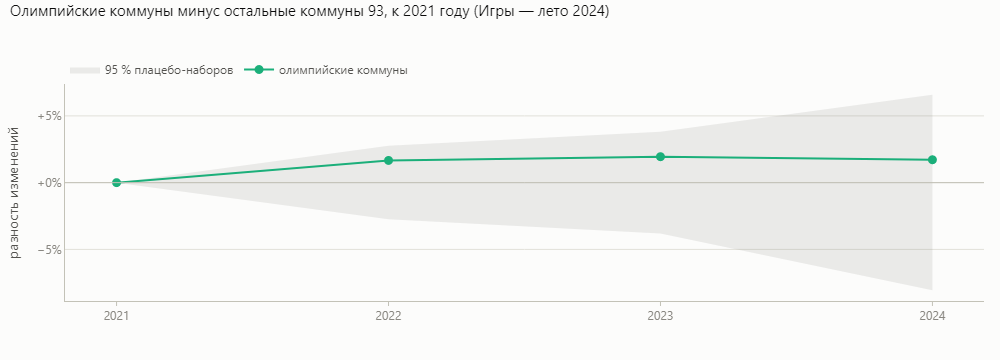

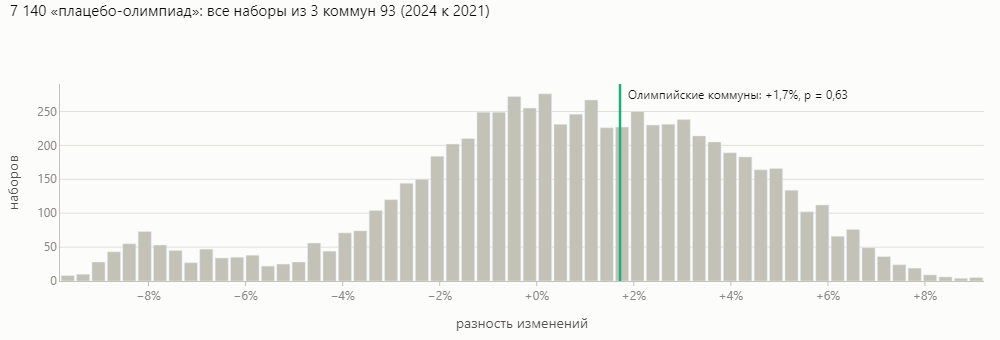

Эффект 2024 к 2021: +1.7%, перестановочный p = 0.632 (7140 наборов); кластерный ДИ [-3.6; +7.5]


In [13]:
o = R["oly"]
show(F.olympics_event(o["event"]))
show(F.olympics_placebo(o["placebo"], o["effect"], o["p"]))
print("Эффект 2024 к 2021: %+.1f%%, перестановочный p = %.3f (%d наборов); кластерный ДИ [%+.1f; %+.1f]"
      % (100 * o["effect"], o["p"], o["n_placebo"], 100 * o["cluster"][1], 100 * o["cluster"][2]))

## 9. Круглые числа и «чуть ниже»

{1000: 0.688, 5000: 0.439, 10000: 0.28, 50000: 0.08, 100000: 0.043}


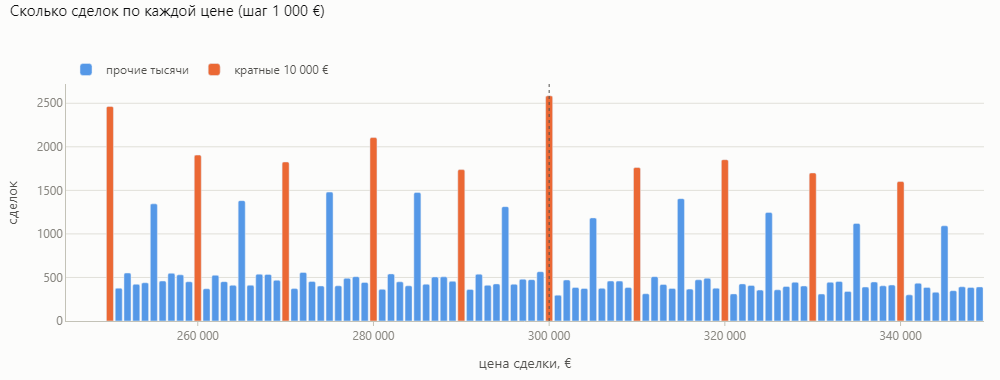

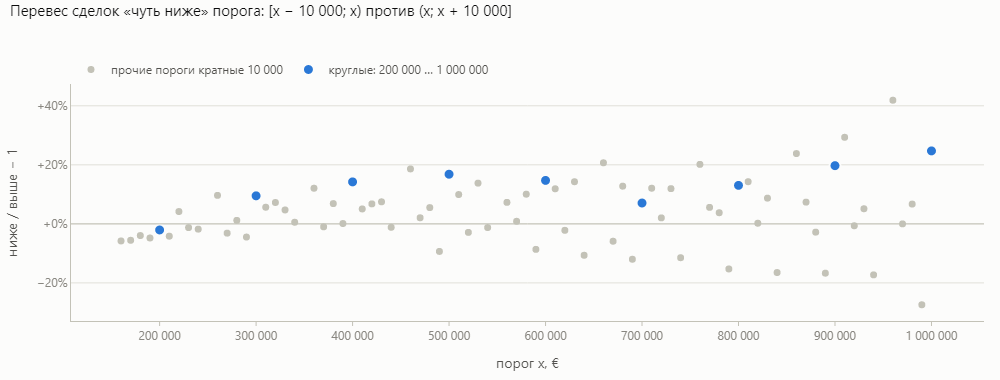

Перевес «ниже»: круглые +12.8%, прочие +2.2%, Манн — Уитни p = 0.0018


In [14]:
rd = R["round"]
print({k: round(x, 3) for k, x in rd["shares"].items()})
show(F.price_hist(rd["hist"]))
show(F.threshold_ratio(rd["r100"], rd["r10"]))
print("Перевес «ниже»: круглые %+.1f%%, прочие %+.1f%%, Манн — Уитни p = %.4f"
      % (100 * rd["excess100"], 100 * rd["excess10"], rd["p"]))

## 10. Сезонность

Объём — сделки в день по месяцам; цена — отклонение помесячного гедонического индекса от
скользящего среднего 2×12 (дамми месяцев с годовыми эффектами путают сезон с внутригодовым трендом).

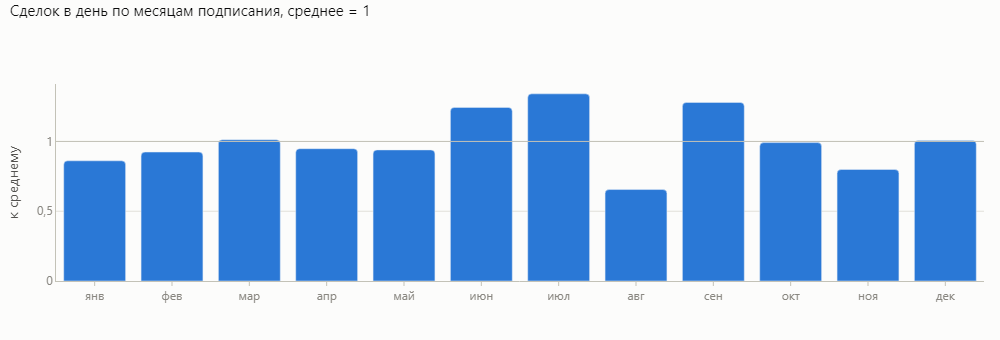

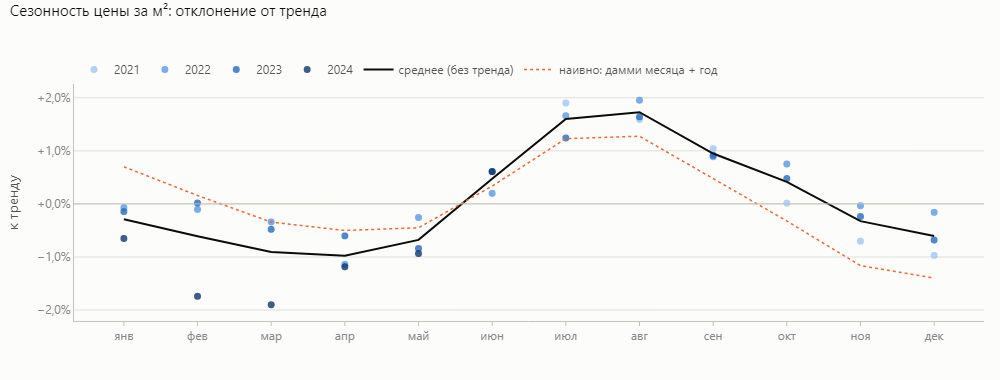

χ² объёма = 11794; F-тест сезонности цены: F = 12.1, p = 2.8e-07


,month,mean,min,max,size
0,1,-0.003,-6.509e-03,-6.971e-04,3
1,2,-0.006,-1.741e-02,1.649e-04,3
2,3,-0.009,-1.900e-02,-3.398e-03,3
3,4,-0.010,-1.184e-02,-6.026e-03,3
4,5,-0.007,-9.358e-03,-2.567e-03,3
5,6,0.005,1.990e-03,6.111e-03,3
6,7,0.016,1.242e-02,1.902e-02,3
7,8,0.017,1.590e-02,1.953e-02,3
8,9,0.009,8.889e-03,1.042e-02,3
9,10,0.004,1.414e-04,7.519e-03,3


In [15]:
se = R["season"]
show(F.season_volume(se["per_day"]))
naive = se["naive"].assign(eff=lambda d: d["eff"] - d["eff"].mean())
show(F.season_price(se["season"], se["spread"], naive))
print("χ² объёма = %.0f; F-тест сезонности цены: F = %.1f, p = %.1e" % (se["chi2"], se["f"], se["f_p"]))
se["spread"]